<div style="background:linear-gradient(90deg,#8e6b23,#d4a73a);padding:26px;border-radius:14px;color:white">
<h4 style="margin:0;opacity:0.9">🧬 AI GENESIS · THE STORY OF AI, ONE ALGORITHM AT A TIME</h4>
<h1 style="margin:6px 0 4px 0">Syllogistic Logic (~350 BCE)</h1>
<p style="margin:0">The first system of rules for <b>correct reasoning</b>, written by Aristotle.</p>
</div>

<br>

| 🪪 Quick card | |
|---|---|
| **Year** | About 350 BCE |
| **Inventor** | Aristotle (384 to 322 BCE), Greek philosopher, in his *Prior Analytics* |
| **Family** | Logic → the first formal reasoning system |
| **Learns from data?** | ❌ No. It checks whether an argument is **valid** |
| **Builds on** | Nothing before it. It is the starting point |
| **Leads to** | Boolean logic (1854), predicate logic (1879), expert systems, Prolog |
| **Difficulty** | ⭐ Beginner |

### 🎯 What you will learn in this notebook
1. What a **syllogism** is, and why logic cares about *form* and not *content*
2. The four kinds of statements: **A, E, I, O**
3. How to build a **validity checker** that tests an argument in every possible world
4. A machine that tests **all 256 syllogism forms** and finds the famous valid ones
5. How to find a **counter-example** that breaks a bad argument
6. A tiny **reasoning engine** that derives new facts automatically (the seed of expert systems)

## 📖 Part 1: The story

Around **350 BCE**, in Athens, **Aristotle** (a student of Plato and the teacher of Alexander the Great) asked a question nobody had asked so carefully:

> *What makes an argument **correct**, regardless of what it is about?*

His answer, in the *Prior Analytics*, was the **syllogism**, an argument made of **two premises and a conclusion**:

> **All men are mortal.**
> **Socrates is a man.**
> **Therefore, Socrates is mortal.**

The key discovery: the argument is valid because of its **shape**. Replace the words and the shape still works:

> **All robots need power. R2 is a robot. Therefore R2 needs power.**

This is the idea of **formal logic**: reasoning can be studied like mathematics, by looking at patterns, without needing to know the topic. That is exactly what a computer does.

### 🏛️ A 2,000-year reign
- For about **two thousand years**, Aristotle's system *was* logic. Medieval scholars in the 13th century gave every valid form a Latin name such as **Barbara** and **Celarent** to help students remember them.
- **1768:** Euler (yes, the same Euler of graph theory) used circles to illustrate syllogisms. They are called Euler diagrams.
- **1854:** George Boole turned logic into algebra, so machines could one day do it.
- **1879:** Gottlob Frege created a much stronger logic that went beyond Aristotle's.
- **1956:** The *Logic Theorist*, one of the first AI programs, proved theorems using logical rules.

### 🗺️ Where this fits
```
Aristotle (350 BCE) → Boole (1854) → Frege (1879) → Logic Theorist (1956) → Prolog (1972) → Expert Systems
```

> 📝 There was another ancient logic too. The **Stoics** (for example Chrysippus, about 3rd century BCE) studied *"if ... then"* and *"or"* statements. That branch is today's propositional logic, and it has its own notebook later.

## 🧠 Part 2: The ideas in plain words

### The four kinds of statements (A, E, I, O)
Aristotle noticed that most useful statements have one of four shapes, built from two groups: a **subject** `S` and a **predicate** `P`.

| Letter | Form | Example | Meaning |
|---|---|---|---|
| **A** | All S are P | All dogs are mammals | every member of S is inside P |
| **E** | No S are P | No fish are mammals | S and P do not overlap |
| **I** | Some S are P | Some pets are dogs | S and P overlap |
| **O** | Some S are not P | Some pets are not dogs | part of S is outside P |

> 🔤 The letters come from the Latin words **AffIrmo** (I affirm: **A**, **I**) and **nEgO** (I deny: **E**, **O**).

### The three parts of a syllogism
- **Major premise**: contains the **predicate** of the conclusion (`P`) and the **middle term** (`M`)
- **Minor premise**: contains the **subject** of the conclusion (`S`) and the middle term (`M`)
- **Conclusion**: connects `S` and `P`. The middle term `M` is the *bridge* and disappears

In our example: `S` = Socrates (or "men"), `P` = mortal, `M` = men.

### The four figures
Where the middle term sits changes the "figure" of the syllogism:

| Figure | Major premise | Minor premise |
|---|---|---|
| **1** | M – P | S – M |
| **2** | P – M | S – M |
| **3** | M – P | M – S |
| **4** | P – M | M – S |

### How many forms exist?
3 statements, each one of 4 types (A, E, I, O) → `4 × 4 × 4 = 64` **moods**. Times 4 figures → **256 possible forms**. Which ones are *valid*? We will let the computer find out.

### 🔑 What does "valid" mean?
An argument is **valid** if there is **no possible world** where both premises are true and the conclusion is false. (It says nothing about whether the premises are actually true.)

## 🟣 Step 1: Import the libraries
> 💡 We only need `itertools` to generate all combinations, `random` for simulation, and `pandas`, `numpy` and `matplotlib` for tables and drawings.

In [1]:
# Import the libraries we need
import itertools
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from matplotlib.colors import ListedColormap

# Styling and a colour palette used across the notebook
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
GOLD, BROWN, GREEN, LIGHTGREEN, RED, BLUE, GREY, DARK = "#d4a73a", "#8e6b23", "#27ae60", "#a9dfbf", "#e74c3c", "#4286f4", "#d5d8dc", "#2c3e50"

print("✅ Libraries ready!")

✅ Libraries ready!


## 🖼️ Step 2: Picture the classic syllogism
> 💡 An **Euler diagram** shows statements as circles. "All men are mortal" means the *men* circle sits **inside** the *mortal* circle. "Socrates is a man" puts Socrates **inside the men circle**. So Socrates must be inside *mortal*. You can *see* the conclusion.

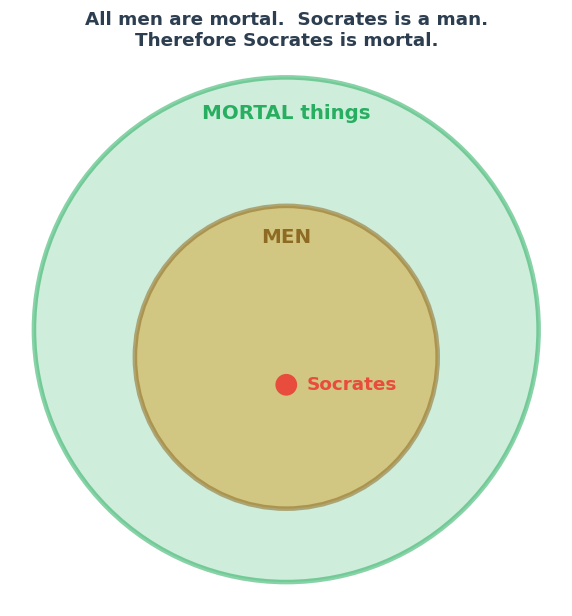

In [2]:
# Draw the Socrates syllogism as nested circles
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.set_xlim(-6, 6); ax.set_ylim(-6, 6); ax.set_aspect("equal"); ax.axis("off")

ax.add_patch(Circle((0, 0), 5.5, color=LIGHTGREEN, alpha=0.55, ec=GREEN, lw=3))
ax.text(0, 4.6, "MORTAL things", ha="center", color=GREEN, fontsize=13, fontweight="bold")

ax.add_patch(Circle((0, -0.6), 3.3, color=GOLD, alpha=0.55, ec=BROWN, lw=3))
ax.text(0, 1.9, "MEN", ha="center", color=BROWN, fontsize=13, fontweight="bold")

ax.add_patch(Circle((0, -1.2), 0.22, color=RED, zorder=5))
ax.text(0.45, -1.2, "Socrates", color=RED, fontsize=12, fontweight="bold", va="center")

ax.set_title("All men are mortal.  Socrates is a man.\nTherefore Socrates is mortal.", color=DARK, fontweight="bold", fontsize=12)
plt.show()

## 🧩 Step 3: Statements and "possible worlds"
> 💡 To test arguments with a computer we need two things:
> 1. **Statements** in the four A/E/I/O shapes.
> 2. **Possible worlds**. With three groups `S`, `P`, `M`, every individual in a world falls into one of **8 regions** (inside or outside each group). A world is simply *which of the 8 regions contain at least one individual*. That gives `2^8 = 256` possible worlds.
>
> A statement is **true or false in a world** by looking at the populated regions:
> - **A** (All X are Y): no populated region is *inside X but outside Y*
> - **E** (No X are Y): no populated region is inside *both*
> - **I** (Some X are Y): some populated region is inside *both*
> - **O** (Some X are not Y): some populated region is inside X but outside Y

In [3]:
# Statements, regions and truth in a possible world
TERMS = ["S", "P", "M"]
REGIONS = list(itertools.product([0, 1], repeat=3))        # (inS, inP, inM) for each of the 8 regions

def term_bit(region, term):
    return region[TERMS.index(term)]

def holds(statement, populated):
    '''Is the statement true in a world? `populated` is the set of non-empty regions.'''
    kind, x, y = statement
    if kind == "A":                                        # All x are y
        return not any(term_bit(r, x) == 1 and term_bit(r, y) == 0 for r in populated)
    if kind == "E":                                        # No x are y
        return not any(term_bit(r, x) == 1 and term_bit(r, y) == 1 for r in populated)
    if kind == "I":                                        # Some x are y
        return any(term_bit(r, x) == 1 and term_bit(r, y) == 1 for r in populated)
    if kind == "O":                                        # Some x are not y
        return any(term_bit(r, x) == 1 and term_bit(r, y) == 0 for r in populated)
    raise ValueError(kind)

def say(statement, names={}):
    kind, x, y = statement
    x, y = names.get(x, x), names.get(y, y)
    return {"A": f"All {x} are {y}", "E": f"No {x} are {y}",
            "I": f"Some {x} are {y}", "O": f"Some {x} are not {y}"}[kind]

# A tiny world: only the regions "S and M but not P" and "P only" are populated
world = {(1, 0, 1), (0, 1, 0)}
for st in [("A", "S", "M"), ("E", "S", "P"), ("I", "S", "M"), ("O", "S", "M")]:
    print(f"{say(st):<22} → {holds(st, world)}")

All S are M            → True
No S are P             → True
Some S are M           → True
Some S are not M       → False


## 🎲 Step 4: Test the Socrates argument in random worlds
> 💡 Before the exact method, a simulation. We build **100,000 random worlds** (random people, each with random properties) and keep only the worlds where **both premises are true**. In how many of them is the conclusion false?
> For a valid argument: **never**.

In [4]:
# Simulate random worlds and test the Socrates argument:  All M are P,  All S are M,  therefore All S are P
rng = random.Random(7)
worlds_tested = premises_true = counterexamples = 0

for _ in range(100_000):
    people = [(rng.random() < 0.5, rng.random() < 0.5, rng.random() < 0.5) for _ in range(rng.randint(1, 6))]
    populated = {tuple(int(v) for v in p) for p in people}       # which regions have someone in them
    worlds_tested += 1
    if holds(("A", "M", "P"), populated) and holds(("A", "S", "M"), populated):      # both premises true
        premises_true += 1
        if not holds(("A", "S", "P"), populated):                                       # conclusion false?
            counterexamples += 1

print(f"Worlds tested:                     {worlds_tested:,}")
print(f"Worlds where both premises hold:   {premises_true:,}")
print(f"Worlds where the conclusion fails: {counterexamples}")

Worlds tested:                     100,000
Worlds where both premises hold:   16,362
Worlds where the conclusion fails: 0


## ✅ Step 5: An exact validity checker
> 💡 Simulation can miss rare cases. But there are only **256 possible worlds**, so we can check **every one**. This is the exact test:
> *an argument is valid if the conclusion is true in every world where both premises are true.*
>
> We also add the traditional **"existential import"** option: Aristotle assumed every group (S, P, M) has **at least one member** (there are really some men, some mortals). Modern logic does not assume this.

In [5]:
# Build a syllogism from its mood (like "AAA") and figure (1 to 4), then test validity in all 256 worlds
FIGURES = {1: (("M", "P"), ("S", "M")),
           2: (("P", "M"), ("S", "M")),
           3: (("M", "P"), ("M", "S")),
           4: (("P", "M"), ("M", "S"))}

def build(mood, figure):
    (a, b), (c, d) = FIGURES[figure]
    major, minor, conclusion = (mood[0], a, b), (mood[1], c, d), (mood[2], "S", "P")
    return major, minor, conclusion

ALL_WORLDS = [frozenset(r for r, keep in zip(REGIONS, bits) if keep) for bits in itertools.product([0, 1], repeat=8)]

def nonempty_terms(populated):
    return all(any(term_bit(r, t) for r in populated) for t in TERMS)

def find_counterexample(mood, figure, existential_import=False):
    major, minor, conclusion = build(mood, figure)
    for populated in ALL_WORLDS:
        if existential_import and not nonempty_terms(populated):
            continue
        if holds(major, populated) and holds(minor, populated) and not holds(conclusion, populated):
            return populated
    return None

def is_valid(mood, figure, existential_import=False):
    return find_counterexample(mood, figure, existential_import) is None

print("Socrates syllogism (AAA, figure 1) valid?  ", is_valid("AAA", 1))
print("Same shape in figure 2 (AAA-2) valid?       ", is_valid("AAA", 2))

Socrates syllogism (AAA, figure 1) valid?   True
Same shape in figure 2 (AAA-2) valid?        False


## 🧮 Step 6: Test all 256 syllogisms
> 💡 4 moods per statement → 64 moods × 4 figures = **256 forms**. We test each one twice: with the modern rule, and with Aristotle's "existential import".

In [6]:
# Test every form
moods = ["".join(m) for m in itertools.product("AEIO", repeat=3)]       # 64 moods
results = []
for figure in (1, 2, 3, 4):
    for mood in moods:
        results.append({"mood": mood, "figure": figure,
                        "valid": is_valid(mood, figure),
                        "valid with import": is_valid(mood, figure, existential_import=True)})
table = pd.DataFrame(results)

total = len(table)
valid_modern = int(table["valid"].sum())
valid_aristotle = int(table["valid with import"].sum())
print(f"Forms tested:                                   {total}")
print(f"Valid (no assumptions):                         {valid_modern}")
print(f"Valid with existential import (Aristotle):      {valid_aristotle}")
print(f"Invalid:                                        {total - valid_aristotle}")

Forms tested:                                   256
Valid (no assumptions):                         15
Valid with existential import (Aristotle):      24
Invalid:                                        232


## 🗺️ Step 7: The map of all 256 syllogisms
> 💡 Each little square is one syllogism form.
> - 🟩 **Dark green**: valid with no assumptions
> - 🟢 **Light green**: valid only if every group has at least one member (Aristotle's assumption)
> - ⬜ **Grey**: invalid
>
> Rows are the two **premises** (for example `AA` means major = A, minor = A). Columns are the **conclusion letter and figure** (for example `A1` means conclusion A in figure 1). So the top-left square `AA` / `A1` is **Barbara**, the Socrates syllogism.

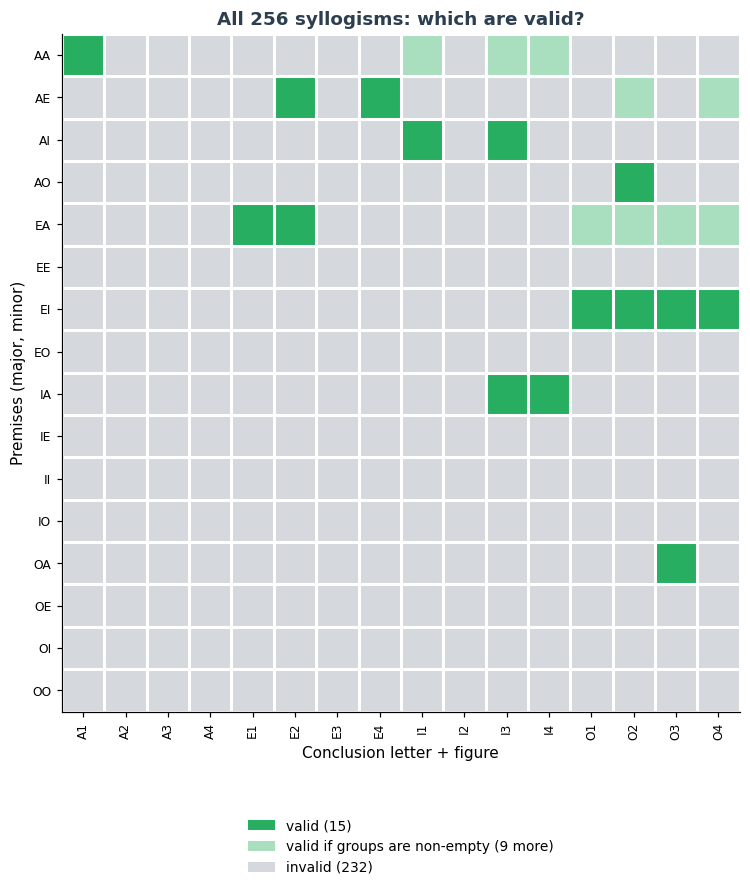

In [7]:
# Draw a 16 x 16 grid of all 256 forms
premise_pairs = ["".join(p) for p in itertools.product("AEIO", repeat=2)]            # 16 rows
conclusion_cols = [(c, f) for c in "AEIO" for f in (1, 2, 3, 4)]                      # 16 columns

grid = np.zeros((16, 16))
for i, pair in enumerate(premise_pairs):
    for j, (concl, figure) in enumerate(conclusion_cols):
        mood = pair + concl
        grid[i, j] = 2 if is_valid(mood, figure) else 1 if is_valid(mood, figure, True) else 0

fig, ax = plt.subplots(figsize=(8.5, 8))
ax.imshow(grid, cmap=ListedColormap([GREY, LIGHTGREEN, GREEN]), vmin=0, vmax=2)
ax.set_xticks(range(16)); ax.set_xticklabels([f"{c}{f}" for c, f in conclusion_cols], rotation=90, fontsize=8)
ax.set_yticks(range(16)); ax.set_yticklabels(premise_pairs, fontsize=8)
ax.set_xticks(np.arange(-0.5, 16, 1), minor=True); ax.set_yticks(np.arange(-0.5, 16, 1), minor=True)
ax.grid(which="minor", color="white", linewidth=2); ax.tick_params(which="minor", length=0)
ax.set_xlabel("Conclusion letter + figure"); ax.set_ylabel("Premises (major, minor)")
ax.set_title("All 256 syllogisms: which are valid?", color=DARK, fontweight="bold")
ax.bar(0, 0, color=GREEN, label=f"valid ({valid_modern})")
ax.bar(0, 0, color=LIGHTGREEN, label=f"valid if groups are non-empty ({valid_aristotle - valid_modern} more)")
ax.bar(0, 0, color=GREY, label=f"invalid ({total - valid_aristotle})")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=1, frameon=False, fontsize=9)
plt.show()

## 🏷️ Step 8: The famous names
> 💡 Medieval students memorised the valid forms using **Latin names**. The **vowels of each name give the mood**: in **B**a**r**b**a**r**a** the vowels are A-A-A; in C**e**l**a**r**e**nt they are E-A-E; in D**a**r**i**i they are A-I-I; in F**e**r**i**o they are E-I-O.
> The **first letter** also hints which Figure-1 form a name can be reduced to. Here are all 24 traditional names, with a check from our computer.

In [8]:
# The 24 traditional names, and a check that our computer agrees with tradition
names = {
    (1, "AAA"): "Barbara", (1, "EAE"): "Celarent", (1, "AII"): "Darii", (1, "EIO"): "Ferio",
    (1, "AAI"): "Barbari", (1, "EAO"): "Celaront",
    (2, "EAE"): "Cesare", (2, "AEE"): "Camestres", (2, "EIO"): "Festino", (2, "AOO"): "Baroco",
    (2, "EAO"): "Cesaro", (2, "AEO"): "Camestrop",
    (3, "IAI"): "Disamis", (3, "AII"): "Datisi", (3, "OAO"): "Bocardo", (3, "EIO"): "Ferison",
    (3, "AAI"): "Darapti", (3, "EAO"): "Felapton",
    (4, "AEE"): "Camenes", (4, "IAI"): "Dimaris", (4, "EIO"): "Fresison",
    (4, "AAI"): "Bramantip", (4, "EAO"): "Fesapo", (4, "AEO"): "Camenop"}

rows = []
for (figure, mood), name in sorted(names.items()):
    major, minor, conclusion = build(mood, figure)
    rows.append({"figure": figure, "mood": mood, "name": name,
                 "valid with no assumptions": "✅" if is_valid(mood, figure) else "—",
                 "needs non-empty groups": "" if is_valid(mood, figure) else "✅"})
names_table = pd.DataFrame(rows)

# Our computer's list of valid forms must equal the traditional list
computed = {(r["figure"], r["mood"]) for _, r in table[table["valid with import"]].iterrows()}
assert computed == set(names), "Mismatch with tradition!"
print(f"✅ Our checker found exactly the {len(names)} classical syllogisms, 2,000 years after Aristotle.")
names_table

✅ Our checker found exactly the 24 classical syllogisms, 2,000 years after Aristotle.


,figure,mood,name,valid with no assumptions,needs non-empty groups
0,1,AAA,Barbara,✅,
1,1,AAI,Barbari,—,✅
2,1,AII,Darii,✅,
3,1,EAE,Celarent,✅,
4,1,EAO,Celaront,—,✅
5,1,EIO,Ferio,✅,
6,2,AEE,Camestres,✅,
7,2,AEO,Camestrop,—,✅
8,2,AOO,Baroco,✅,
9,2,EAE,Cesare,✅,


## ❌ Step 9: Break a bad argument with a counter-example
> 💡 A *counter-example* is a world where the premises are true but the conclusion is false. One counter-example is enough to prove an argument **invalid**.
>
> Look at this argument (figure 2, mood AAA):
> *All cats are animals. All dogs are animals. Therefore all dogs are cats.*
> It *sounds* logical, but it is the classic **undistributed middle** mistake: sharing a group ("animals") does not make two groups the same.

In [9]:
# Find and describe a counter-example
names_map = {"S": "dogs", "P": "cats", "M": "animals"}
major, minor, conclusion = build("AAA", 2)
print("Major premise:", say(major, names_map))
print("Minor premise:", say(minor, names_map))
print("Conclusion:   ", say(conclusion, names_map))

counter = find_counterexample("AAA", 2)
print("\nValid?", counter is None)
print("\nA counter-example world (the groups of individuals that exist):")
for region in sorted(counter):
    inside = [names_map[t] for t, bit in zip(TERMS, region) if bit]
    print("  • something that is:", " and ".join(inside) if inside else "none of the three")
print("\nHere both premises are true, but the conclusion is false: that world has dogs that are not cats.")

Major premise: All cats are animals
Minor premise: All dogs are animals
Conclusion:    All dogs are cats

Valid? False

A counter-example world (the groups of individuals that exist):
  • something that is: dogs and animals

Here both premises are true, but the conclusion is false: that world has dogs that are not cats.


## 🔗 Step 10: A tiny reasoning engine
> 💡 Here is the AI part. Instead of testing one argument, let the computer **derive new facts by itself** from a knowledge base, using four valid forms we just verified:
>
> | Rule | Name | Pattern |
> |---|---|---|
> | All x are y, All y are z → All x are z | Barbara (AAA-1) | chain |
> | No y are z, All x are y → No x are z | Celarent (EAE-1) | exclude |
> | All y are z, Some x are y → Some x are z | Darii (AII-1) | overlap |
> | No y are z, Some x are y → Some x are not z | Ferio (EIO-1) | partial exclude |
>
> The engine keeps applying the rules until nothing new appears. This is **forward chaining**, the heart of the *expert systems* of the 1970s.

In [10]:
# Check that the four rules we will use are really valid, then run the forward-chaining engine
for mood, name in [("AAA", "Barbara"), ("EAE", "Celarent"), ("AII", "Darii"), ("EIO", "Ferio")]:
    assert is_valid(mood, 1), name
print("✅ The four rules are valid syllogisms.\n")

knowledge = {("A", "dogs", "mammals"), ("A", "cats", "mammals"), ("A", "mammals", "animals"),
             ("A", "animals", "living things"), ("E", "fish", "mammals"),
             ("I", "pets", "dogs"), ("A", "puppies", "dogs")}
start = set(knowledge)

changed = True
while changed:
    changed = False
    facts = list(knowledge)
    new = set()
    for k1, x1, y1 in facts:
        for k2, x2, y2 in facts:
            if k1 == "A" and k2 == "A" and y1 == x2:                       # Barbara
                new.add(("A", x1, y2))
            if k1 == "E" and k2 == "A" and x1 == y2:                       # Celarent: No y are z, All x are y
                new.add(("E", x2, y1))
            if k1 == "A" and k2 == "I" and x1 == y2:                       # Darii: All y are z, Some x are y
                new.add(("I", x2, y1))
            if k1 == "E" and k2 == "I" and x1 == y2:                       # Ferio: No y are z, Some x are y
                new.add(("O", x2, y1))
    if not new <= knowledge:
        knowledge |= new
        changed = True

print("Facts we started with:")
for st in sorted(start):
    print("  •", say(st))
print("\nNew facts the engine derived by itself:")
for st in sorted(knowledge - start):
    print("  ✨", say(st))

✅ The four rules are valid syllogisms.

Facts we started with:
  • All animals are living things
  • All cats are mammals
  • All dogs are mammals
  • All mammals are animals
  • All puppies are dogs
  • No fish are mammals
  • Some pets are dogs

New facts the engine derived by itself:
  ✨ All cats are animals
  ✨ All cats are living things
  ✨ All dogs are animals
  ✨ All dogs are living things
  ✨ All mammals are living things
  ✨ All puppies are animals
  ✨ All puppies are living things
  ✨ All puppies are mammals
  ✨ Some pets are animals
  ✨ Some pets are living things
  ✨ Some pets are mammals


## ⚠️ Limitations of Aristotle's logic

| Limitation | What it means | Who fixed it |
|---|---|---|
| ❌ **Only four statement shapes** | Cannot express "Alice is taller than Bob" or "Every student has a teacher" (relations) | Predicate logic (Frege, 1879) |
| ❌ **No "if ... then", "or", "not" between whole statements** | Cannot handle everyday reasoning like "if it rains, the road is wet" | Stoic logic, Boole (1854), propositional logic |
| ❌ **Existential import** | "All unicorns are white" is awkward: does it imply unicorns exist? | Boole and modern logic drop this assumption |
| ❌ **Words are fixed by hand** | The computer needs a person to write the statements in A/E/I/O form | Natural language processing (much later) |
| ❌ **Certainty only** | Valid or invalid, nothing in between | Probability and Bayes' theorem |

### 🧬 What it gave us
- The idea that **reasoning has a form that can be checked mechanically**
- Terms we still use: *premise, conclusion, valid, fallacy, counter-example*
- The seed of **automated deduction**, expert systems and logic programming

## 📝 Summary
1. ✅ A **syllogism** has two premises and a conclusion, built from four statement types **A, E, I, O**.
2. ✅ An argument is **valid** if no possible world makes the premises true and the conclusion false.
3. ✅ Of **256** possible forms, exactly **15** are valid with no assumptions, and **24** if every group is non-empty. Our checker matched Aristotle's tradition.
4. ✅ A **counter-example** proves an argument invalid.
5. ✅ Valid rules can be applied automatically to **derive new knowledge**.

## 🧪 Practice time
**Exercise 1.** Is this valid? *Some pets are dogs. All dogs are loyal. Therefore some pets are loyal.* Name the mood and figure.

**Exercise 2.** Is this valid? *All politicians are liars. Some liars are rich. Therefore some politicians are rich.* If not, find a counter-example.

**Exercise 3.** Add the facts `("A", "reptiles", "animals")` and `("E", "reptiles", "mammals")` to the knowledge base in Step 10. What new fact appears about reptiles?

<details>
<summary>👀 Click to see the solutions</summary>

```python
# Exercise 1: major = "All dogs are loyal" (M-P), minor = "Some pets are dogs" (S-M), conclusion "Some pets are loyal"
# mood = A (major), I (minor), I (conclusion) → AII, figure 1 → Darii
print(is_valid("AII", 1))     # True

# Exercise 2: major = "Some liars are rich" (M-P), minor = "All politicians are liars" (S-M), conclusion "Some politicians are rich"
# mood = I, A, I → IAI, figure 1
print(is_valid("IAI", 1))     # False
c = find_counterexample("IAI", 1)
print(sorted(c))              # a world where some liars are rich, but those rich liars are not politicians

# Exercise 3: "No reptiles are mammals" is already given; the engine can derive new facts such as
# "All reptiles are living things" (Barbara). Re-run Step 10 with the two extra facts to see them.
```
</details>

## ⏭️ What's next in AI-Genesis
Next stop on the road: **What is an Algorithm? (al-Khwarizmi, about 820 CE)**, the Baghdad scholar whose name gave us the word *algorithm*. 🚀